# Bank Term Deposit Classification

**Subject:** Machine Learning Assignment 2

**Name:** Assignment 2

**Bits ID:** 2026AJ05749

## Problem Statement

The objective of this project is to develop and compare five machine learning classification models to predict whether a bank customer will subscribe to a term deposit based on customer information and marketing campaign details.

The project also includes an interactive Streamlit application that allows users to upload test data, select a classification model and view its evaluation results.

## Models

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

## Evaluation Metrics

- Accuracy
- AUC Score
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

In [ ]:
!pip install -q ucimlrepo pandas numpy matplotlib seaborn scikit-learn joblib streamlit

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Download Bank Marketing dataset
bank_marketing = fetch_ucirepo(id=222)

# Extract input features and target
X = bank_marketing.data.features
y = bank_marketing.data.targets

# Combine features and target
df = pd.concat([X, y], axis=1)

# Rename target column
df.rename(columns={y.columns[0]: "y"}, inplace=True)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [ ]:
print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nDataset columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (45211, 17)

First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no



Dataset columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     

In [ ]:
print("Target distribution:")
print(df["y"].value_counts())

print("\nTarget percentage:")
print(df["y"].value_counts(normalize=True) * 100)

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [ ]:
df.to_csv(
    "Bank_Term_Deposit_Classification.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Missing values in each column:
age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64

Duplicate records: 0


In [ ]:
# Remove duration because it is known only after the marketing call
df = df.drop(columns=["duration"])

print("Duration column removed successfully!")

print("Updated dataset shape:", df.shape)

print("\nRemaining columns:")
print(df.columns.tolist())

Duration column removed successfully!
Updated dataset shape: (45211, 16)

Remaining columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [ ]:
# Input features
X = df.drop(columns=["y"])

# Target variable
y = df["y"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.unique())

print("\nNumber of input features:", X.shape[1])

Input features shape: (45211, 15)
Target shape: (45211,)

Target classes:
['no' 'yes']

Number of input features: 15


In [ ]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal numerical features:", len(numerical_features))
print("Total categorical features:", len(categorical_features))

Numerical features:
['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Total numerical features: 6
Total categorical features: 9


In [ ]:
print("Numerical feature summary:")
display(X[numerical_features].describe())

print("\nCategorical feature summary:")
display(X[categorical_features].describe())

Numerical feature summary:


,age,balance,day_of_week,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,63.000000,871.000000,275.000000



Categorical feature summary:


,job,marital,education,default,housing,loan,contact,month,poutcome
count,44923,45211,43354,45211,45211,45211,32191,45211,8252
unique,11,3,3,2,2,2,2,12,3
top,blue-collar,married,secondary,no,yes,no,cellular,may,failure
freq,9732,27214,23202,44396,25130,37967,29285,13766,4901


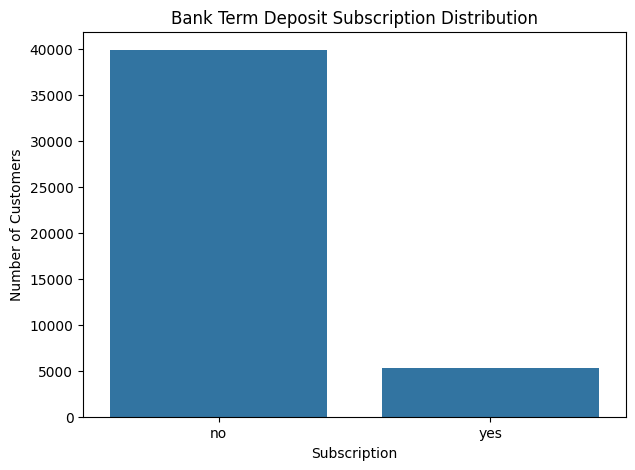

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y"
)

plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

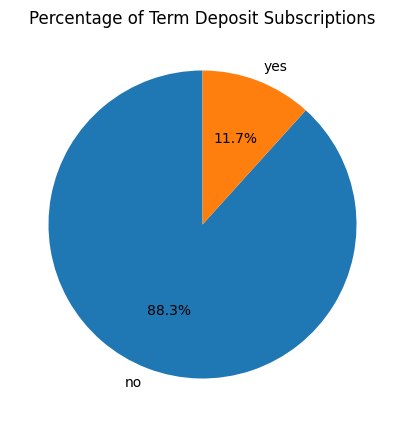

In [ ]:
target_percentage = (
    df["y"].value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 5))

plt.pie(
    target_percentage,
    labels=target_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Term Deposit Subscriptions")
plt.show()

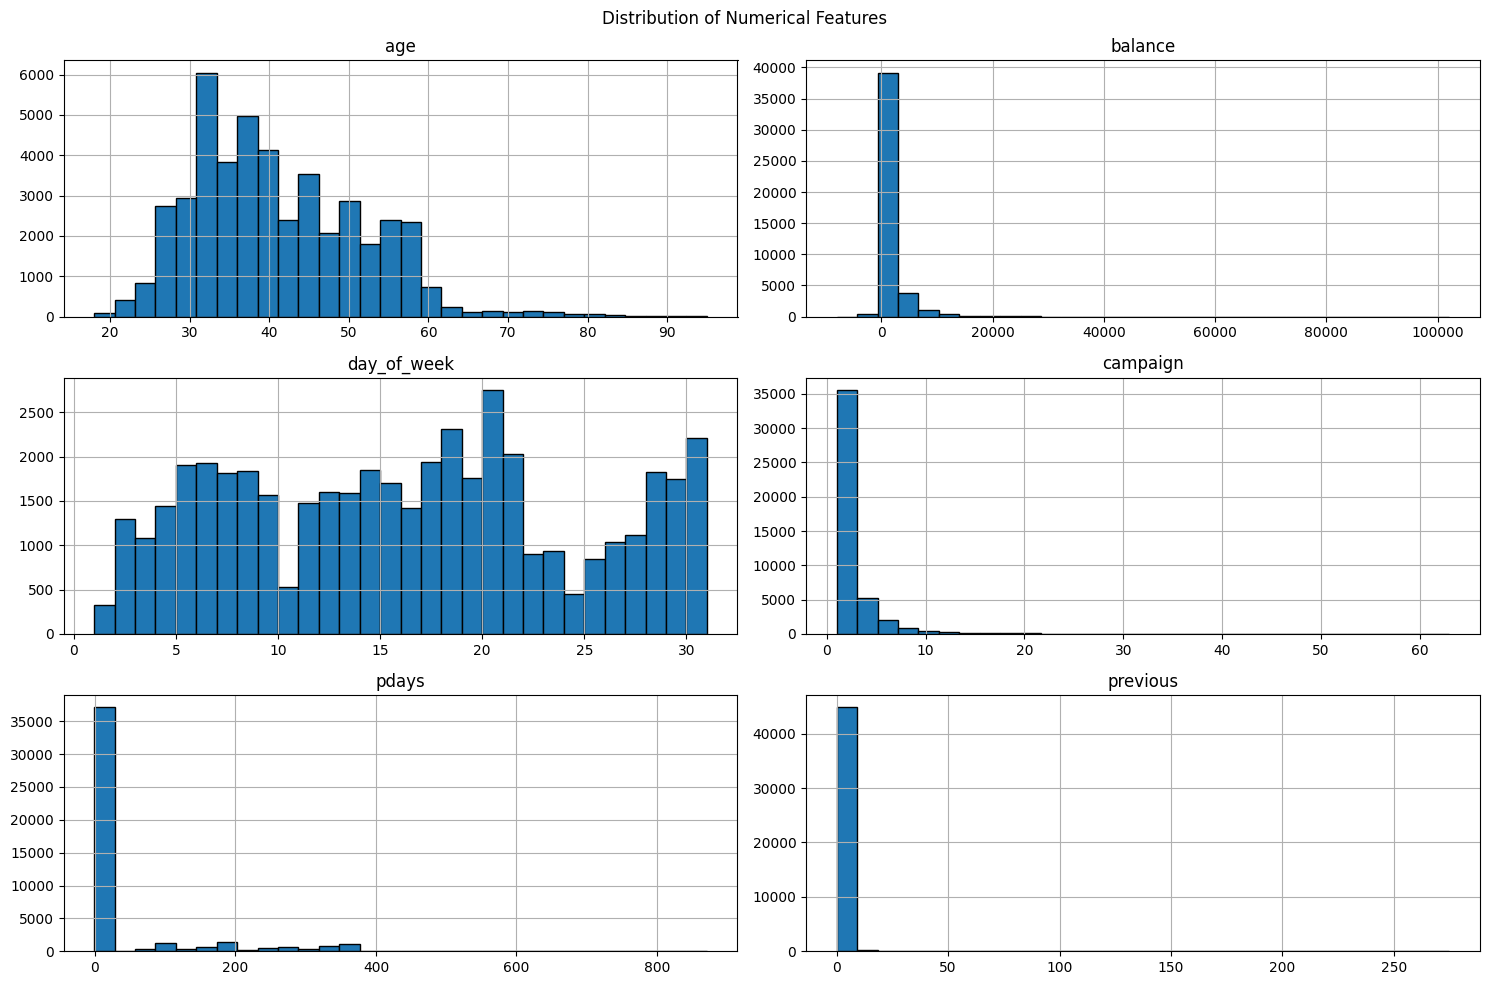

In [ ]:
df[numerical_features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

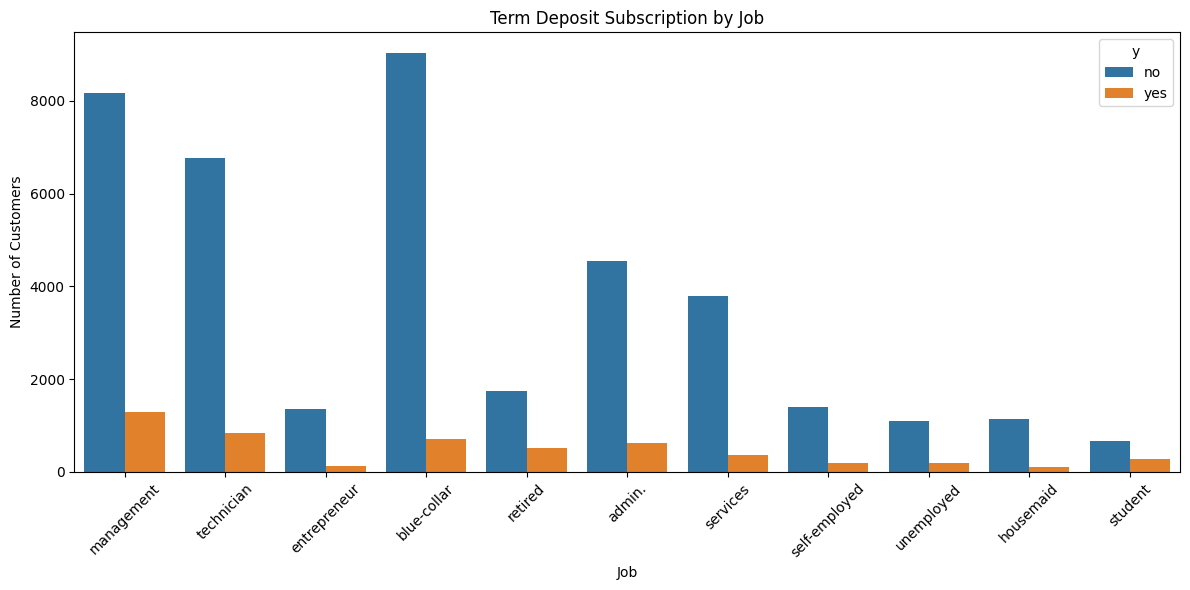

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="job",
    hue="y"
)

plt.title("Term Deposit Subscription by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

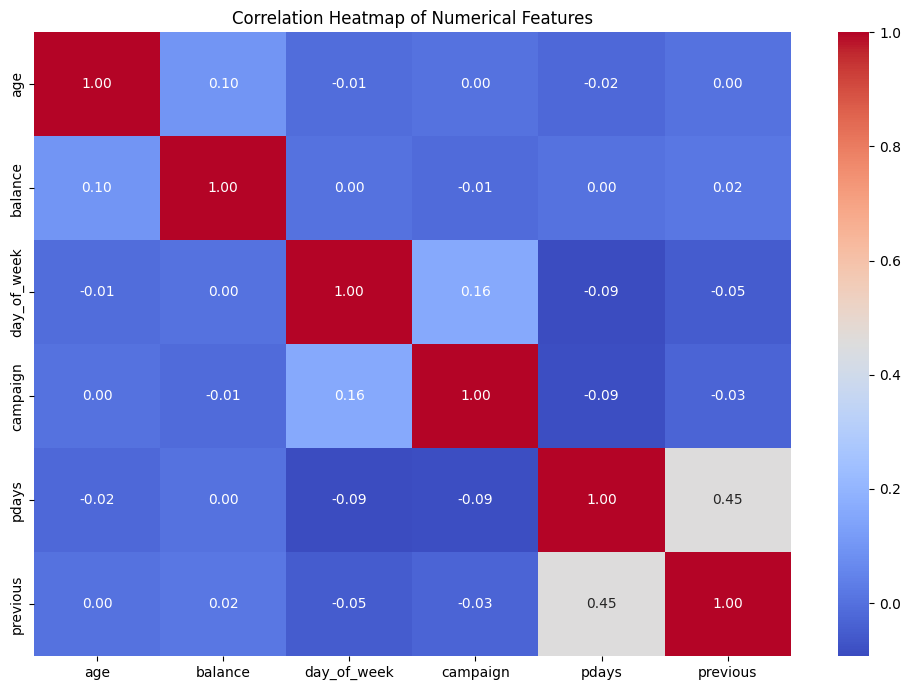

In [ ]:
plt.figure(figsize=(10, 7))

correlation = df[numerical_features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [ ]:
# Separate input and target
X = df.drop(columns=["y"])
y = df["y"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training data shape: (36168, 15)
Testing data shape: (9043, 15)

Training target distribution:
y
no     88.301814
yes    11.698186
Name: proportion, dtype: float64

Testing target distribution:
y
no     88.300343
yes    11.699657
Name: proportion, dtype: float64


In [ ]:
# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import time
import joblib

print("All machine learning algorithms imported successfully!")

All machine learning algorithms imported successfully!


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    )
}

print("Five classification models created successfully!")

for model_name in models:
    print("-", model_name)

Five classification models created successfully!
- Logistic Regression
- Decision Tree
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Support Vector Machine


In [ ]:
trained_models = {}
training_times = {}

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    # Create a complete preprocessing and model pipeline
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    start_time = time.time()

    # Train model
    pipeline.fit(X_train, y_train)

    end_time = time.time()

    # Store trained pipeline
    trained_models[model_name] = pipeline

    # Store training time
    training_times[model_name] = round(
        end_time - start_time, 2
    )

    print(
        f"{model_name} trained successfully "
        f"in {training_times[model_name]} seconds"
    )

print("\nAll five models have been trained!")


Training: Logistic Regression
Logistic Regression trained successfully in 1.32 seconds

Training: Decision Tree
Decision Tree trained successfully in 0.94 seconds

Training: K-Nearest Neighbors
K-Nearest Neighbors trained successfully in 0.36 seconds

Training: Gaussian Naive Bayes
Gaussian Naive Bayes trained successfully in 0.36 seconds

Training: Support Vector Machine
Support Vector Machine trained successfully in 1.48 seconds

All five models have been trained!


In [ ]:
results = []

for model_name, model in trained_models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate prediction scores for AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Convert target into binary format for AUC
    y_test_binary = (y_test == "yes").astype(int)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test_binary,
        y_score
    )

    precision = precision_score(
        y_test,
        y_pred,
        pos_label="yes",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        pos_label="yes",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        pos_label="yes",
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_test,
        y_pred
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc,
        "Training Time (seconds)": training_times[model_name]
    })

    print(f"{model_name} evaluated successfully!")

# Create comparison dataframe
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON RESULTS")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "MCC": "{:.4f}",
        "Training Time (seconds)": "{:.2f}"
    })
)

Logistic Regression evaluated successfully!
Decision Tree evaluated successfully!
K-Nearest Neighbors evaluated successfully!
Gaussian Naive Bayes evaluated successfully!
Support Vector Machine evaluated successfully!

MODEL COMPARISON RESULTS


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC,Training Time (seconds)
0,Logistic Regression,0.7548,0.7722,0.2662,0.6238,0.3732,0.2853,1.32
1,Decision Tree,0.8316,0.7188,0.3518,0.5217,0.4203,0.3347,0.94
2,K-Nearest Neighbors,0.8874,0.7027,0.5529,0.1975,0.2911,0.2833,0.36
3,Gaussian Naive Bayes,0.8452,0.7514,0.3708,0.4641,0.4123,0.3271,0.36
4,Support Vector Machine,0.7578,0.7718,0.2684,0.6200,0.3746,0.2867,1.48


In [ ]:
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

print("Best model for each evaluation metric:\n")

for metric in metrics:

    best_index = results_df[metric].idxmax()

    best_model = results_df.loc[
        best_index, "Model"
    ]

    best_score = results_df.loc[
        best_index, metric
    ]

    print(
        f"{metric}: {best_model} ({best_score:.4f})"
    )

Best model for each evaluation metric:

Accuracy: K-Nearest Neighbors (0.8874)
AUC: Logistic Regression (0.7722)
Precision: K-Nearest Neighbors (0.5529)
Recall: Logistic Regression (0.6238)
F1 Score: Decision Tree (0.4203)
MCC: Decision Tree (0.3347)


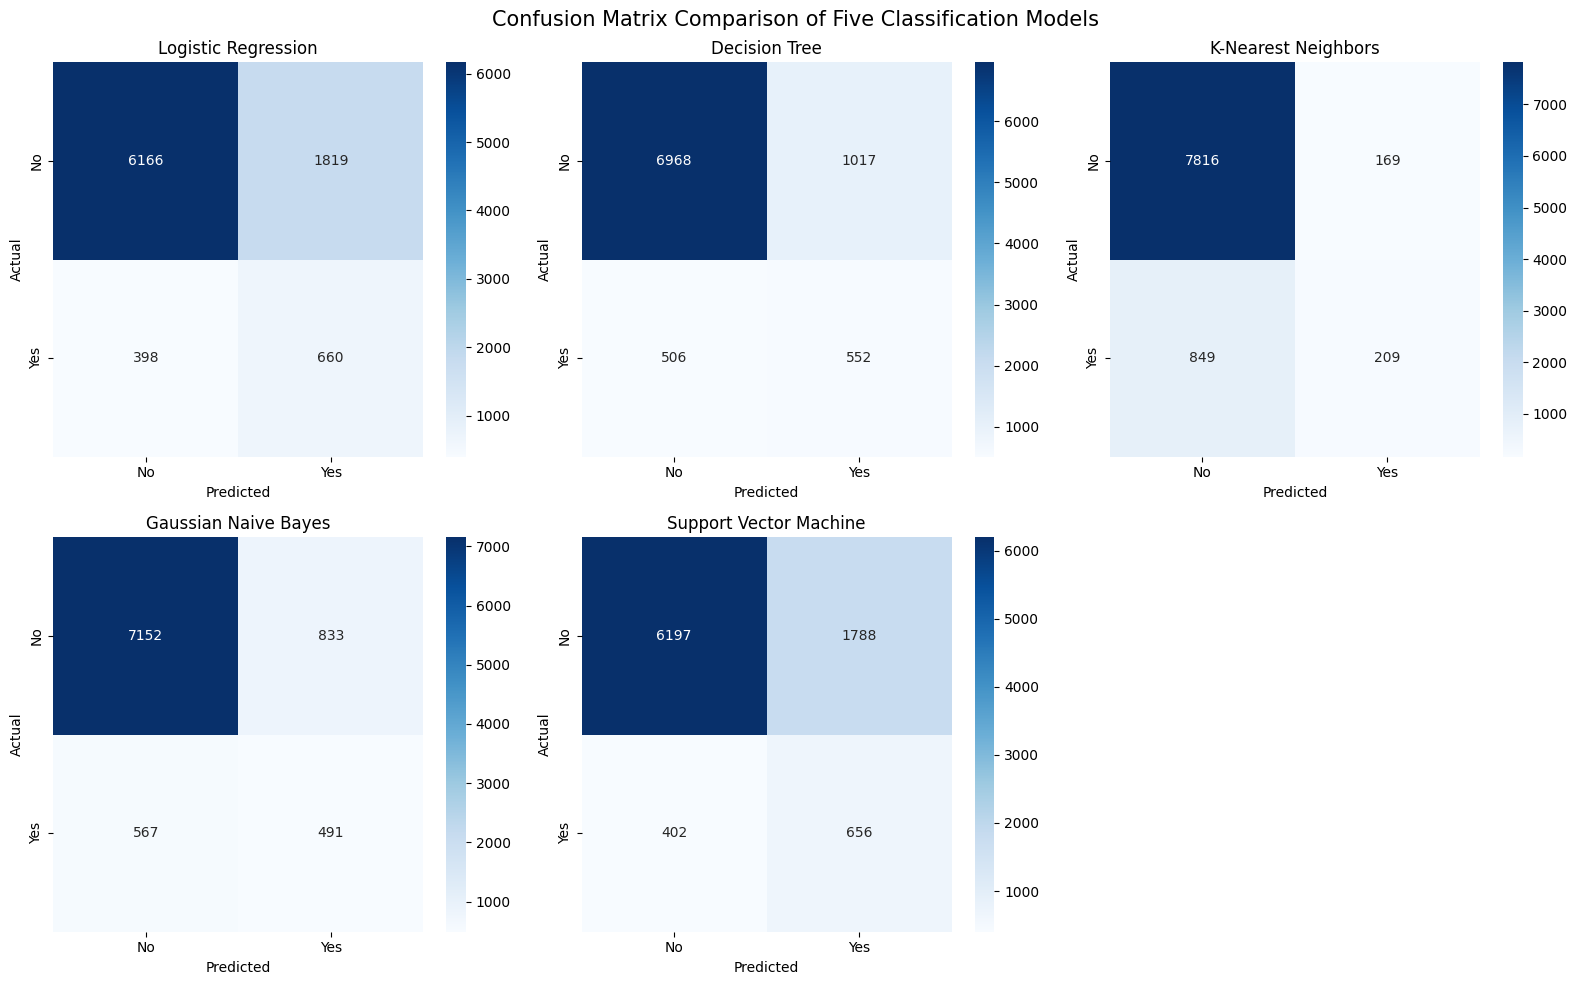

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (model_name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["no", "yes"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[5].axis("off")

plt.suptitle(
    "Confusion Matrix Comparison of Five Classification Models",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
for model_name, model in trained_models.items():

    print("\n" + "=" * 65)
    print("MODEL:", model_name)
    print("=" * 65)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=["no", "yes"],
            zero_division=0
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

          no       0.94      0.77      0.85      7985
         yes       0.27      0.62      0.37      1058

    accuracy                           0.75      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.75      0.79      9043


MODEL: Decision Tree
              precision    recall  f1-score   support

          no       0.93      0.87      0.90      7985
         yes       0.35      0.52      0.42      1058

    accuracy                           0.83      9043
   macro avg       0.64      0.70      0.66      9043
weighted avg       0.86      0.83      0.85      9043


MODEL: K-Nearest Neighbors
              precision    recall  f1-score   support

          no       0.90      0.98      0.94      7985
         yes       0.55      0.20      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.73      0.59      0.61      9

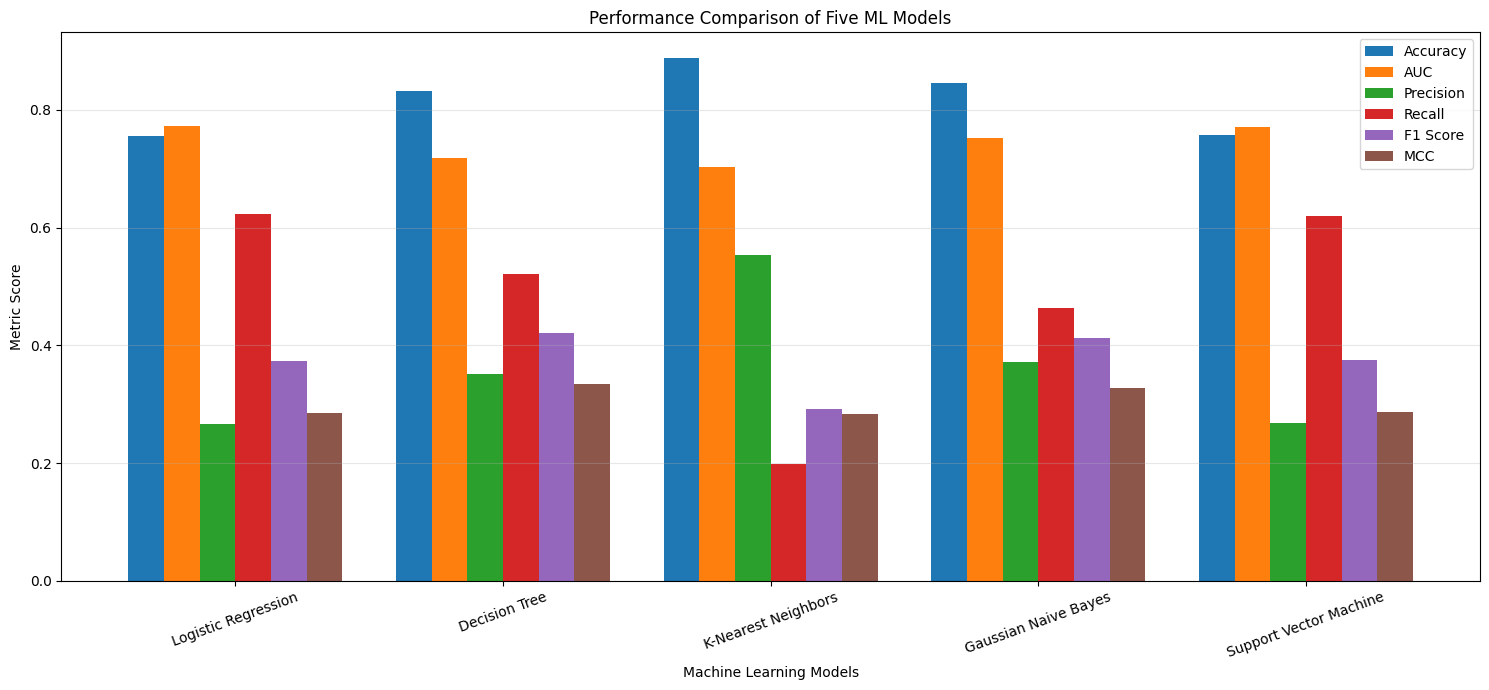

In [ ]:
comparison_metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

results_plot = results_df.set_index("Model")[
    comparison_metrics
]

results_plot.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title("Performance Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Metric Score")
plt.xticks(rotation=20)
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import os

folders = [
    "Bank_Term_Deposit_Project",
    "Bank_Term_Deposit_Project/model",
    "Bank_Term_Deposit_Project/data",
    "Bank_Term_Deposit_Project/visualizations"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
import joblib

model_path = "Bank_Term_Deposit_Project/model"

for model_name, model in trained_models.items():

    filename = (
        model_name.lower()
        .replace(" ", "_")
        + ".pkl"
    )

    joblib.dump(
        model,
        os.path.join(model_path, filename)
    )

    print(f"{model_name} saved successfully!")

Logistic Regression saved successfully!
Decision Tree saved successfully!
K-Nearest Neighbors saved successfully!
Gaussian Naive Bayes saved successfully!
Support Vector Machine saved successfully!


In [ ]:
test_data = X_test.copy()

# Add actual target values
test_data["y"] = y_test.values

test_data.to_csv(
    "Bank_Term_Deposit_Project/data/test_data.csv",
    index=False
)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

display(test_data.head())

Test dataset saved successfully!
Test dataset shape: (9043, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,campaign,pdays,previous,poutcome,y
1392,40,blue-collar,married,primary,no,640,yes,yes,NaN,8,may,2,-1,0,NaN,no
7518,44,technician,married,secondary,no,378,yes,no,NaN,30,may,2,-1,0,NaN,no
12007,31,services,married,secondary,no,356,yes,no,NaN,20,jun,5,-1,0,NaN,no
5536,36,blue-collar,married,primary,no,655,yes,no,NaN,23,may,4,-1,0,NaN,no
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,NaN,no


In [ ]:
results_df.to_csv(
    "Bank_Term_Deposit_Project/model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


<Figure size 1500x700 with 0 Axes>

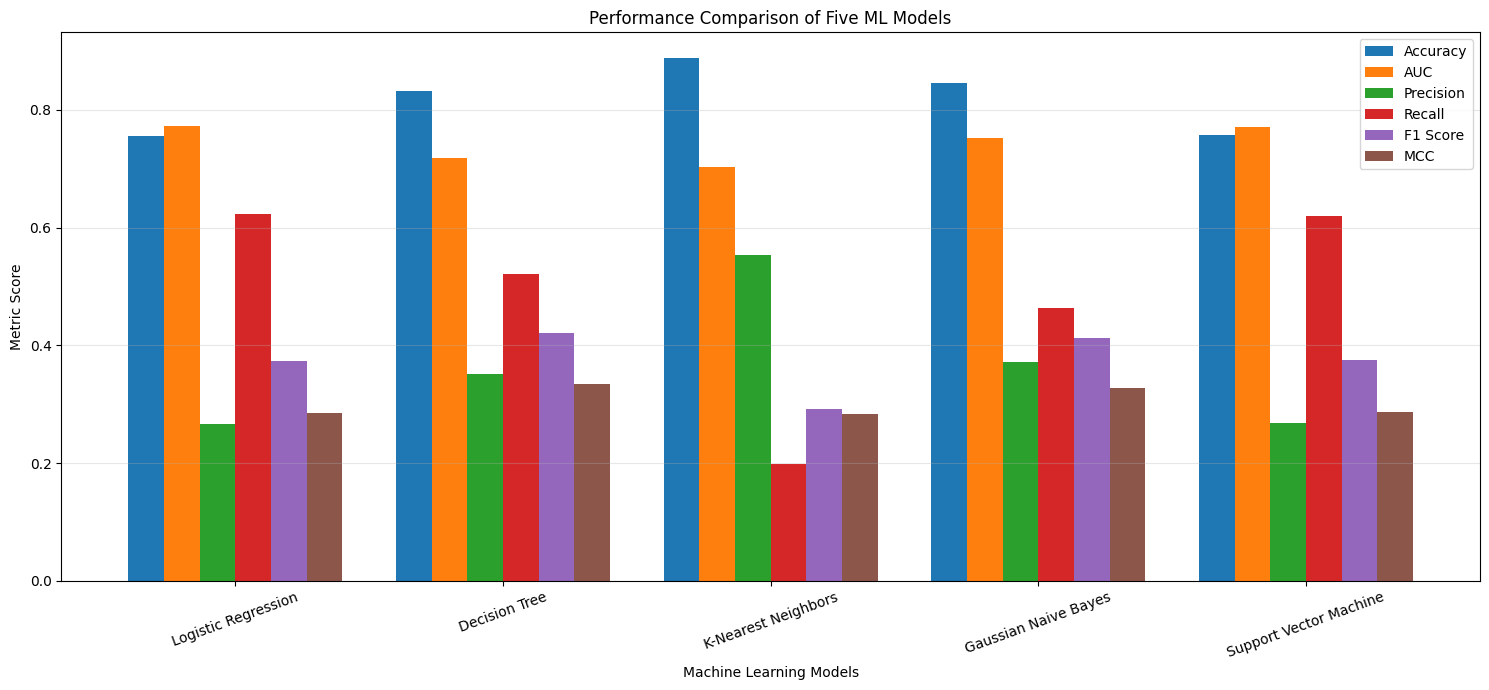

Comparison graph saved successfully!


In [ ]:
plt.figure(figsize=(15, 7))

results_plot.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title("Performance Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Metric Score")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Bank_Term_Deposit_Project/visualizations/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison graph saved successfully!")

In [ ]:
for root, dirs, files in os.walk("Bank_Term_Deposit_Project"):
    level = root.replace(
        "Bank_Term_Deposit_Project", ""
    ).count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Bank_Term_Deposit_Project/
    model_comparison.csv
    data/
        test_data.csv
    model/
        gaussian_naive_bayes.pkl
        logistic_regression.pkl
        support_vector_machine.pkl
        decision_tree.pkl
        k-nearest_neighbors.pkl
    visualizations/
        model_comparison.png


In [ ]:
%%writefile Bank_Term_Deposit_Project/app.py

import os
import joblib
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Bank Analytics | Term Deposit AI",
    page_icon="🏦",
    layout="wide",
    initial_sidebar_state="expanded"
)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_DIR = os.path.join(BASE_DIR, "model")
DATA_DIR = os.path.join(BASE_DIR, "data")

# --------------------------------------------------
# CUSTOM STYLING
# --------------------------------------------------

st.markdown("""
<style>

.stApp {
    background-color: #F4F7FB;
}

[data-testid="stSidebar"] {
    background-color: #14213D;
}

[data-testid="stSidebar"] * {
    color: white;
}

.main-title {
    font-size: 32px;
    font-weight: 800;
    color: #14213D;
}

.subtitle {
    color: #64748B;
    font-size: 15px;
}

.metric-card {
    background: white;
    padding: 22px;
    border-radius: 14px;
    border: 1px solid #E2E8F0;
    box-shadow: 0 3px 12px rgba(15, 23, 42, 0.04);
}

.metric-label {
    color: #64748B;
    font-size: 13px;
}

.metric-value {
    color: #14213D;
    font-size: 28px;
    font-weight: 800;
}

.section-title {
    color: #14213D;
    font-size: 23px;
    font-weight: 700;
}

div.stButton > button {
    background-color: #2563EB;
    color: white;
    border-radius: 9px;
    border: none;
    padding: 10px 20px;
    font-weight: 600;
}

div.stButton > button:hover {
    background-color: #1D4ED8;
    color: white;
}

</style>
""", unsafe_allow_html=True)


# --------------------------------------------------
# LOAD TRAINED MODELS
# --------------------------------------------------

MODEL_FILES = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "K-Nearest Neighbors": "k-nearest_neighbors.pkl",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.pkl",
    "Support Vector Machine": "support_vector_machine.pkl"
}

@st.cache_resource
def load_models():

    loaded = {}

    for name, filename in MODEL_FILES.items():

        path = os.path.join(MODEL_DIR, filename)

        if os.path.exists(path):
            loaded[name] = joblib.load(path)

    return loaded


models = load_models()


# --------------------------------------------------
# LOAD SAMPLE TEST DATA
# --------------------------------------------------

@st.cache_data
def load_sample_data():

    path = os.path.join(DATA_DIR, "test_data.csv")

    if os.path.exists(path):
        return pd.read_csv(path)

    return None


sample_data = load_sample_data()


# --------------------------------------------------
# SIDEBAR NAVIGATION
# --------------------------------------------------

st.sidebar.markdown("# 🏦 BANK AI")
st.sidebar.markdown("### Analytics Platform")
st.sidebar.markdown("---")

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "Overview",
        "Model Performance",
        "Model Evaluation",
        "Customer Prediction",
        "Test Dataset"
    ]
)

st.sidebar.markdown("---")
st.sidebar.markdown("### Project Information")
st.sidebar.caption("Bank Term Deposit Classification")
st.sidebar.caption("Machine Learning Assignment 2")
st.sidebar.caption("Five Classification Algorithms")


# --------------------------------------------------
# HELPER FUNCTIONS
# --------------------------------------------------

def metric_card(label, value):

    st.markdown(
        f"""
        <div class="metric-card">
            <div class="metric-label">{label}</div>
            <div class="metric-value">{value}</div>
        </div>
        """,
        unsafe_allow_html=True
    )


def evaluate_models(data):

    if "y" not in data.columns:
        raise ValueError(
            "The uploaded CSV must contain the target column 'y'."
        )

    X = data.drop(columns=["y"])
    y_true = data["y"].astype(str).str.lower()

    if not set(y_true.unique()).issubset({"yes", "no"}):
        raise ValueError(
            "Target column 'y' must contain only yes/no values."
        )

    if set(y_true.unique()) != {"yes", "no"}:
        raise ValueError(
            "The uploaded dataset must contain both yes and no classes "
            "to calculate all evaluation metrics."
        )

    results = []
    predictions = {}

    for name, model in models.items():

        y_pred = model.predict(X)

        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X)[:, 1]
        else:
            y_score = model.decision_function(X)

        y_binary = (y_true == "yes").astype(int)

        result = {
            "Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "AUC": roc_auc_score(y_binary, y_score),
            "Precision": precision_score(
                y_true, y_pred, pos_label="yes", zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, pos_label="yes", zero_division=0
            ),
            "F1 Score": f1_score(
                y_true, y_pred, pos_label="yes", zero_division=0
            ),
            "MCC": matthews_corrcoef(y_true, y_pred)
        }

        results.append(result)
        predictions[name] = y_pred

    return pd.DataFrame(results), predictions, y_true


# --------------------------------------------------
# PAGE 1: OVERVIEW
# --------------------------------------------------

if page == "Overview":

    st.markdown(
        '<div class="main-title">Bank Analytics Dashboard</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">AI-powered customer term deposit classification</div>',
        unsafe_allow_html=True
    )

    st.write("")

    st.markdown("""
    This platform evaluates five machine learning algorithms
    to predict whether a bank customer is likely to subscribe
    to a term deposit.
    """)

    c1, c2, c3, c4 = st.columns(4)

    with c1:
        metric_card("Dataset Records", "45,211")

    with c2:
        metric_card("Input Features", "15")

    with c3:
        metric_card("ML Models", "5")

    with c4:
        metric_card("Target Classes", "2")

    st.write("")

    st.markdown(
        '<div class="section-title">Project Overview</div>',
        unsafe_allow_html=True
    )

    col1, col2 = st.columns(2)

    with col1:

        st.markdown("### Classification Objective")

        st.write(
            "Predict whether a customer will subscribe to a "
            "bank term deposit using customer information "
            "and marketing campaign features."
        )

        st.markdown("### Target Variable")

        st.info("y = yes / no")

    with col2:

        st.markdown("### Machine Learning Algorithms")

        for name in MODEL_FILES:
            st.write("• " + name)

    st.write("")

    st.markdown("### Evaluation Metrics")

    st.write(
        "Accuracy | AUC | Precision | Recall | F1 Score | MCC"
    )

    if not models:
        st.error("No trained models were found. Check the model folder.")


# --------------------------------------------------
# PAGE 2: MODEL PERFORMANCE
# --------------------------------------------------

elif page == "Model Performance":

    st.markdown(
        '<div class="main-title">Model Performance</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">Comparison of all five trained algorithms</div>',
        unsafe_allow_html=True
    )

    comparison_path = os.path.join(
        BASE_DIR, "model_comparison.csv"
    )

    if os.path.exists(comparison_path):

        results = pd.read_csv(comparison_path)

        st.dataframe(
            results,
            use_container_width=True,
            hide_index=True
        )

        metric = st.selectbox(
            "Select Evaluation Metric",
            [
                "Accuracy", "AUC", "Precision",
                "Recall", "F1 Score", "MCC"
            ]
        )

        fig = px.bar(
            results,
            x="Model",
            y=metric,
            color="Model",
            text_auto=".4f",
            title=f"{metric} Comparison"
        )

        fig.update_layout(
            template="plotly_white",
            showlegend=False,
            height=480
        )

        st.plotly_chart(fig, use_container_width=True)

        st.markdown("### Overall Metric Comparison")

        melted = results.melt(
            id_vars="Model",
            value_vars=[
                "Accuracy", "AUC", "Precision",
                "Recall", "F1 Score", "MCC"
            ],
            var_name="Metric",
            value_name="Score"
        )

        fig2 = px.bar(
            melted,
            x="Model",
            y="Score",
            color="Metric",
            barmode="group",
            title="All Evaluation Metrics"
        )

        fig2.update_layout(template="plotly_white")

        st.plotly_chart(fig2, use_container_width=True)

    else:
        st.warning("Model comparison file not found.")


# --------------------------------------------------
# PAGE 3: MODEL EVALUATION
# --------------------------------------------------

elif page == "Model Evaluation":

    st.markdown(
        '<div class="main-title">Model Evaluation</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">Detailed evaluation on test data</div>',
        unsafe_allow_html=True
    )

    if sample_data is None:
        st.warning("Sample test dataset not found.")
    else:

        selected_model = st.selectbox(
            "Choose Classification Model",
            list(models.keys())
        )

        model = models[selected_model]

        X_eval = sample_data.drop(columns=["y"])
        y_true = sample_data["y"].astype(str).str.lower()

        y_pred = model.predict(X_eval)

        y_binary = (y_true == "yes").astype(int)

        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_eval)[:, 1]
        else:
            y_score = model.decision_function(X_eval)

        m1, m2, m3 = st.columns(3)

        with m1:
            metric_card(
                "Accuracy",
                f"{accuracy_score(y_true, y_pred):.4f}"
            )

        with m2:
            metric_card(
                "AUC",
                f"{roc_auc_score(y_binary, y_score):.4f}"
            )

        with m3:
            metric_card(
                "F1 Score",
                f"{f1_score(y_true, y_pred, pos_label='yes'):.4f}"
            )

        st.write("")

        cm = confusion_matrix(
            y_true, y_pred, labels=["no", "yes"]
        )

        fig = px.imshow(
            cm,
            text_auto=True,
            x=["Predicted No", "Predicted Yes"],
            y=["Actual No", "Actual Yes"],
            color_continuous_scale="Blues",
            title=f"{selected_model} - Confusion Matrix"
        )

        st.plotly_chart(fig, use_container_width=True)

        st.markdown("### Classification Report")

        report = classification_report(
            y_true,
            y_pred,
            labels=["no", "yes"],
            output_dict=True,
            zero_division=0
        )

        st.dataframe(
            pd.DataFrame(report).transpose(),
            use_container_width=True
        )


# --------------------------------------------------
# PAGE 4: CUSTOMER PREDICTION
# --------------------------------------------------

elif page == "Customer Prediction":

    st.markdown(
        '<div class="main-title">Customer Prediction</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">Predict subscription using customer details</div>',
        unsafe_allow_html=True
    )

    st.info(
        "Enter customer details to receive a prediction "
        "from your selected trained model."
    )

    with st.form("customer_form"):

        col1, col2, col3 = st.columns(3)

        with col1:

            age = st.number_input(
                "Age", min_value=18, max_value=100, value=35
            )

            job = st.selectbox(
                "Job",
                [
                    "admin.", "blue-collar", "entrepreneur",
                    "housemaid", "management", "retired",
                    "self-employed", "services", "student",
                    "technician", "unemployed", "unknown"
                ]
            )

            marital = st.selectbox(
                "Marital Status",
                ["married", "single", "divorced"]
            )

            education = st.selectbox(
                "Education",
                ["primary", "secondary", "tertiary", "unknown"]
            )

            default = st.selectbox(
                "Credit in Default", ["no", "yes", "unknown"]
            )

        with col2:

            balance = st.number_input(
                "Account Balance", value=1000
            )

            housing = st.selectbox(
                "Housing Loan", ["yes", "no", "unknown"]
            )

            loan = st.selectbox(
                "Personal Loan", ["no", "yes", "unknown"]
            )

            contact = st.selectbox(
                "Contact Type", ["cellular", "telephone", "unknown"]
            )

            day = st.number_input(
                "Day of Week (1–31)",
                min_value=1, max_value=31, value=15
            )

        with col3:

            month = st.selectbox(
                "Month",
                [
                    "jan", "feb", "mar", "apr", "may",
                    "jun", "jul", "aug", "sep",
                    "oct", "nov", "dec"
                ]
            )

            campaign = st.number_input(
                "Number of Contacts",
                min_value=1, value=1
            )

            pdays = st.number_input(
                "Days Since Previous Contact",
                min_value=-1, value=-1
            )

            previous = st.number_input(
                "Previous Contacts",
                min_value=0, value=0
            )

            poutcome = st.selectbox(
                "Previous Campaign Outcome",
                ["unknown", "failure", "other", "success"]
            )

        selected_model = st.selectbox(
            "Select Model",
            list(models.keys()),
            key="prediction_model"
        )

        submit = st.form_submit_button(
            "Predict Subscription",
            use_container_width=True
        )

    if submit:

        input_data = pd.DataFrame([{
            "age": age,
            "job": job,
            "marital": marital,
            "education": education,
            "default": default,
            "balance": balance,
            "housing": housing,
            "loan": loan,
            "contact": contact,
            "day_of_week": day,
            "month": month,
            "campaign": campaign,
            "pdays": pdays,
            "previous": previous,
            "poutcome": poutcome
        }])

        model = models[selected_model]

        prediction = model.predict(input_data)[0]

        st.write("")

        if prediction == "yes":
            st.success(
                "Prediction: Customer is likely to subscribe (YES)."
            )
        else:
            st.warning(
                "Prediction: Customer is unlikely to subscribe (NO)."
            )

        st.caption(
            "This is a machine learning prediction, not a guarantee "
            "of customer behavior."
        )


# --------------------------------------------------
# PAGE 5: TEST DATASET UPLOAD
# --------------------------------------------------

elif page == "Test Dataset":

    st.markdown(
        '<div class="main-title">Test Dataset Evaluation</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">Upload a labeled CSV and evaluate all five models</div>',
        unsafe_allow_html=True
    )

    st.info(
        "Upload a CSV containing the 15 input features and "
        "the actual target column 'y' (yes/no)."
    )

    uploaded_file = st.file_uploader(
        "Upload Test CSV",
        type=["csv"]
    )

    if uploaded_file is not None:

        try:

            uploaded_data = pd.read_csv(uploaded_file)

            st.markdown("### Uploaded Dataset Preview")

            st.dataframe(
                uploaded_data.head(),
                use_container_width=True
            )

            if st.button("Evaluate All Models"):

                results, predictions, y_true = evaluate_models(
                    uploaded_data
                )

                st.markdown("### Model Comparison Results")

                st.dataframe(
                    results.style.format({
                        col: "{:.4f}"
                        for col in [
                            "Accuracy", "AUC", "Precision",
                            "Recall", "F1 Score", "MCC"
                        ]
                    }),
                    use_container_width=True
                )

                fig = px.bar(
                    results.melt(
                        id_vars="Model",
                        value_vars=[
                            "Accuracy", "AUC", "Precision",
                            "Recall", "F1 Score", "MCC"
                        ],
                        var_name="Metric",
                        value_name="Score"
                    ),
                    x="Model",
                    y="Score",
                    color="Metric",
                    barmode="group",
                    title="Uploaded Dataset - Model Comparison"
                )

                st.plotly_chart(
                    fig,
                    use_container_width=True
                )

                selected = st.selectbox(
                    "Select Model for Detailed Evaluation",
                    list(models.keys())
                )

                selected_pred = predictions[selected]

                cm = confusion_matrix(
                    y_true,
                    selected_pred,
                    labels=["no", "yes"]
                )

                fig_cm = px.imshow(
                    cm,
                    text_auto=True,
                    x=["Predicted No", "Predicted Yes"],
                    y=["Actual No", "Actual Yes"],
                    color_continuous_scale="Blues",
                    title=f"{selected} - Confusion Matrix"
                )

                st.plotly_chart(
                    fig_cm,
                    use_container_width=True
                )

                report = classification_report(
                    y_true,
                    selected_pred,
                    labels=["no", "yes"],
                    output_dict=True,
                    zero_division=0
                )

                st.markdown("### Classification Report")

                st.dataframe(
                    pd.DataFrame(report).transpose(),
                    use_container_width=True
                )

                st.success(
                    "Evaluation completed. Models were not retrained."
                )

        except Exception as error:
            st.error(f"Evaluation error: {error}")


# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.markdown("---")

st.markdown(
    """
    <div style="text-align:center;color:#64748B;padding:10px;">
        Bank Term Deposit Classification |
        Machine Learning Assignment 2
    </div>
    """,
    unsafe_allow_html=True
)

Writing Bank_Term_Deposit_Project/app.py


In [ ]:
%%writefile /content/Bank_Term_Deposit_Project/requirements.txt
streamlit
pandas
numpy==2.4.6
scikit-learn==1.6.1
joblib==1.6.0
plotly
matplotlib
seaborn

Overwriting /content/Bank_Term_Deposit_Project/requirements.txt


In [ ]:
%%writefile Bank_Term_Deposit_Project/README.md

# Bank Term Deposit Classification

## 1. Problem Statement

The objective of this project is to develop and compare five machine learning classification algorithms to predict whether a bank customer will subscribe to a term deposit.

The project also provides an interactive Streamlit application for model evaluation and customer prediction.

## 2. Dataset Description

Dataset Name: Bank Marketing Dataset

Source: UCI Machine Learning Repository

Dataset Link:
https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing

Dataset Details:
- Total Records: 45,211
- Original Input Features: 16
- Features Used: 15
- Target Variable: y
- Classification Type: Binary Classification
- Target Classes: yes / no

The duration feature was excluded because it is only known after the marketing call.

## 3. Machine Learning Models

Five classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine (LinearSVC)

## 4. Data Preprocessing

- Numerical features were standardized using StandardScaler.
- Categorical features were encoded using OneHotEncoder.
- The dataset was divided into 80% training and 20% testing data.
- Stratified sampling was used to preserve the target class distribution.
- Preprocessing was included inside each model pipeline to prevent data leakage.

## 5. Model Evaluation

The following evaluation metrics were calculated:

- Accuracy
- AUC
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

### Model Comparison Results

| Model | Accuracy | AUC | Precision | Recall | F1 Score | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.7548 | 0.7722 | 0.2662 | 0.6238 | 0.3732 | 0.2853 |
| Decision Tree | 0.8316 | 0.7188 | 0.3518 | 0.5217 | 0.4203 | 0.3347 |
| K-Nearest Neighbors | 0.8874 | 0.7027 | 0.5529 | 0.1975 | 0.2911 | 0.2833 |
| Gaussian Naive Bayes | 0.8452 | 0.7514 | 0.3708 | 0.4641 | 0.4123 | 0.3271 |
| Support Vector Machine | 0.7578 | 0.7718 | 0.2684 | 0.6200 | 0.3746 | 0.2867 |

## 6. Model Observations

### Logistic Regression
Achieved the highest AUC score of 0.7722 and the highest recall of 0.6238. It showed good ability to distinguish between customers who subscribe and those who do not.

### Decision Tree
Achieved the highest F1 score of 0.4203 and MCC of 0.3347. It provided the strongest balance according to these two metrics.

### K-Nearest Neighbors
Achieved the highest accuracy of 0.8874 and precision of 0.5529. However, its recall was only 0.1975, meaning it missed many actual subscribers.

### Gaussian Naive Bayes
Achieved an accuracy of 0.8452 and an F1 score of 0.4123. It demonstrated competitive performance compared with the other models.

### Support Vector Machine
Achieved an AUC score of 0.7718, close to Logistic Regression. Its recall was 0.6200.

## 7. Overall Model Comparison and Conclusion

The Decision Tree model achieved the highest F1 score and MCC among the five models. Therefore, it is the leading candidate when considering these two measures together.

Logistic Regression achieved the highest AUC, while KNN achieved the highest accuracy.

The results demonstrate that accuracy alone is not sufficient for evaluating an imbalanced classification problem. Multiple evaluation metrics provide a more complete understanding of model performance.

## 8. Application Features

The Streamlit application provides:

- Interactive analytics dashboard
- Comparison of five machine learning models
- Evaluation metrics visualization
- Confusion matrix
- Classification report
- Customer subscription prediction
- CSV test dataset upload and evaluation

Uploaded test data is used for evaluation. The application does not retrain the saved models.

## 9. GitHub Repository

[Add your GitHub repository URL here]

## 10. Live Streamlit Application

[Add your deployed Streamlit application URL here]

## 11. Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Plotly
- Streamlit
- Joblib

Writing Bank_Term_Deposit_Project/README.md


In [ ]:
import py_compile

app_path = "Bank_Term_Deposit_Project/app.py"

try:
    py_compile.compile(app_path, doraise=True)
    print("SUCCESS: app.py syntax is correct!")
except Exception as e:
    print("ERROR:", e)

SUCCESS: app.py syntax is correct!


In [ ]:
import os

project_path = "Bank_Term_Deposit_Project"

required_files = [
    "app.py",
    "requirements.txt",
    "README.md",
    "model_comparison.csv",
    "data/test_data.csv",
    "visualizations/model_comparison.png",
    "model/logistic_regression.pkl",
    "model/decision_tree.pkl",
    "model/k-nearest_neighbors.pkl",
    "model/gaussian_naive_bayes.pkl",
    "model/support_vector_machine.pkl"
]

print("PROJECT FILE VERIFICATION\n")

all_found = True

for file in required_files:
    full_path = os.path.join(project_path, file)
    exists = os.path.exists(full_path)

    print(("✓ " if exists else "✗ ") + file)

    if not exists:
        all_found = False

print("\nAll required files present:", all_found)

PROJECT FILE VERIFICATION

✓ app.py
✓ requirements.txt
✓ README.md
✓ model_comparison.csv
✓ data/test_data.csv
✓ visualizations/model_comparison.png
✓ model/logistic_regression.pkl
✓ model/decision_tree.pkl
✓ model/k-nearest_neighbors.pkl
✓ model/gaussian_naive_bayes.pkl
✓ model/support_vector_machine.pkl

All required files present: True


In [ ]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders in current directory:")
print(os.listdir("."))

print("\nChecking /content:")
if os.path.exists("/content"):
    print(os.listdir("/content"))

Current working directory:
/content

Files and folders in current directory:
['.config', 'Bank_Term_Deposit_Classification.csv', 'Bank_Term_Deposit_Project', 'sample_data']

Checking /content:
['.config', 'Bank_Term_Deposit_Classification.csv', 'Bank_Term_Deposit_Project', 'sample_data']


In [ ]:
import os

search_name = "Bank_Term_Deposit_Project"
found = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if search_name in dirs:
        found.append(os.path.join(root, search_name))

print("Search results:")

if found:
    for path in found:
        print("FOUND:", path)
else:
    print("Project folder not found in Google Drive.")

Search results:
Project folder not found in Google Drive.


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if "Bank" in file and file.endswith(".ipynb"):
            print(os.path.join(root, file))

In [ ]:
import os

print("Checking project folders...\n")

for root, dirs, files in os.walk("/content"):
    if "Bank_Term_Deposit_Project" in dirs:
        print("Project found at:", os.path.join(root, "Bank_Term_Deposit_Project"))

Checking project folders...

Project found at: /content/Bank_Term_Deposit_Project


In [ ]:
import shutil
import os

source = "/content/Bank_Term_Deposit_Project"
destination = "/content/drive/MyDrive/Bank_Term_Deposit_Project"

if os.path.exists(destination):
    shutil.rmtree(destination)

shutil.copytree(source, destination)

print("SUCCESS: Project backed up to Google Drive!")
print("Location:", destination)

print("\nProject files:")
for root, dirs, files in os.walk(destination):
    for file in files:
        print(os.path.relpath(os.path.join(root, file), destination))

SUCCESS: Project backed up to Google Drive!
Location: /content/drive/MyDrive/Bank_Term_Deposit_Project

Project files:
model_comparison.csv
app.py
README.md
requirements.txt
data/test_data.csv
model/gaussian_naive_bayes.pkl
model/logistic_regression.pkl
model/support_vector_machine.pkl
model/decision_tree.pkl
model/k-nearest_neighbors.pkl
visualizations/model_comparison.png
__pycache__/app.cpython-313.pyc


In [ ]:
import os
import subprocess

PROJECT_PATH = "/content/Bank_Term_Deposit_Project"

print("Project exists:", os.path.exists(PROJECT_PATH))

result = subprocess.run(
    ["git", "--version"],
    capture_output=True,
    text=True
)

print("Git:", result.stdout)
print("Git error:", result.stderr)

Project exists: True
Git: git version 2.43.0

Git error: 


In [ ]:
!git config --global user.name "TiwariAnshika20"
!git config --global user.email "2026aj05749@wilp.bits-pilani.ac.in"
!git config --global --list

user.name=TiwariAnshika20
user.email=2026aj05749@wilp.bits-pilani.ac.in


In [ ]:
%cd /content/Bank_Term_Deposit_Project
!pwd
!ls -la

/content/Bank_Term_Deposit_Project
/content/Bank_Term_Deposit_Project
total 56
drwxr-xr-x 6 root root  4096 Nov  4 16:13 .
drwxr-xr-x 1 root root  4096 Nov  4 16:15 ..
-rw-r--r-- 1 root root 19996 Nov  4 16:13 app.py
drwxr-xr-x 2 root root  4096 Nov  4 16:13 data
drwxr-xr-x 2 root root  4096 Nov  4 16:13 model
-rw-r--r-- 1 root root   774 Nov  4 16:13 model_comparison.csv
drwxr-xr-x 2 root root  4096 Nov  4 16:13 __pycache__
-rw-r--r-- 1 root root  4031 Nov  4 16:13 README.md
-rw-r--r-- 1 root root    70 Nov  4 16:13 requirements.txt
drwxr-xr-x 2 root root  4096 Nov  4 16:13 visualizations


In [ ]:
!git init
!git add .
!git status

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/Bank_Term_Deposit_Project/.git/
On branch master

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   README.md
	new file:   __pycache__/app.cpython-313.pyc
	new file:   app.py
	new file:   data/test_data.csv
	new file:   model/decision_tree.pkl
	new file:   model/gaussian_naive_bayes.pkl
	new file:   model/k-nearest_neighbors.pkl
	new file:   model/logistic_regression.pkl
	new file:   model/support_vector_machine.pkl

In [ ]:
import os
import subprocess

PROJECT_PATH = "/content/Bank_Term_Deposit_Project"

# Create .gitignore
gitignore_content = """
__pycache__/
*.pyc
.ipynb_checkpoints/
.env
"""

with open(os.path.join(PROJECT_PATH, ".gitignore"), "w") as f:
    f.write(gitignore_content)

# Remove Python cache from Git tracking
subprocess.run(
    ["git", "rm", "-r", "--cached", "--ignore-unmatch", "__pycache__"],
    cwd=PROJECT_PATH,
    capture_output=True
)

# Set branch name
subprocess.run(
    ["git", "branch", "-M", "main"],
    cwd=PROJECT_PATH,
    check=True
)

# Stage clean project
subprocess.run(
    ["git", "add", "."],
    cwd=PROJECT_PATH,
    check=True
)

print("Project cleaned and ready!")

Project cleaned and ready!


In [ ]:
import os
import subprocess
import getpass

PROJECT_PATH = "/content/Bank_Term_Deposit_Project"

USERNAME = "TiwariAnshika20"
REPO = "Bank_Term_Deposit_Classification"

EMAIL = input("Enter your GitHub email: ")
TOKEN = getpass.getpass("Enter your GitHub token: ")

def run_git(command, env=None):
    return subprocess.run(
        command,
        cwd=PROJECT_PATH,
        env=env,
        capture_output=True,
        text=True
    )

# Configure Git
run_git(["git", "config", "user.name", USERNAME])
run_git(["git", "config", "user.email", EMAIL])

# Configure remote
remote = f"https://github.com/{USERNAME}/{REPO}.git"

existing = run_git(["git", "remote", "get-url", "origin"])

if existing.returncode == 0:
    run_git(["git", "remote", "set-url", "origin", remote])
else:
    run_git(["git", "remote", "add", "origin", remote])

# Commit
status = run_git(["git", "diff", "--cached", "--quiet"])

if status.returncode == 1:
    commit = run_git([
        "git", "commit", "-m",
        "Bank Term Deposit Classification project"
    ])
    if commit.returncode != 0:
        raise Exception(commit.stderr)

# Secure authentication
askpass = "/content/github_askpass.sh"

with open(askpass, "w") as f:
    f.write("""#!/bin/sh
case "$1" in
    *Username*) echo "x-access-token" ;;
    *Password*) echo "$GITHUB_TOKEN" ;;
    *) echo "" ;;
esac
""")

os.chmod(askpass, 0o700)

env = os.environ.copy()
env["GITHUB_TOKEN"] = TOKEN
env["GIT_ASKPASS"] = askpass
env["GIT_TERMINAL_PROMPT"] = "0"

try:
    result = run_git(
        ["git", "push", "-u", "origin", "main"],
        env=env
    )

    if result.returncode == 0:
        print("SUCCESS! Project uploaded to GitHub.")
        print(remote)
    else:
        print("Upload failed:")
        print(result.stderr)

finally:
    if os.path.exists(askpass):
        os.remove(askpass)

    env.pop("GITHUB_TOKEN", None)
    TOKEN = None

Enter your GitHub email: 2026aj05749@wilp.bits-pilani.ac.in
Enter your GitHub token: ··········
SUCCESS! Project uploaded to GitHub.
https://github.com/TiwariAnshika20/Bank_Term_Deposit_Classification.git


In [ ]:
import sys
import sklearn
import numpy
import joblib

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
NumPy: 2.4.6
Joblib: 1.6.0


In [ ]:
import os
import subprocess

project_path = "/content/Bank_Term_Deposit_Project"
os.chdir(project_path)

print("Git remote:")
subprocess.run(["git", "remote", "-v"])

print("\nGit status:")
subprocess.run(["git", "status", "--short"])

Git remote:

Git status:


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
import os
import subprocess

os.chdir("/content/Bank_Term_Deposit_Project")

commands = [
    ["git", "rev-parse", "--is-inside-work-tree"],
    ["git", "remote"],
    ["git", "status", "--short"],
    ["git", "branch", "--show-current"]
]

for cmd in commands:
    result = subprocess.run(cmd, capture_output=True, text=True)
    print("\nCOMMAND:", " ".join(cmd))
    print("OUTPUT:", result.stdout.strip())
    print("ERROR:", result.stderr.strip())
    print("EXIT CODE:", result.returncode)


COMMAND: git rev-parse --is-inside-work-tree
OUTPUT: true
ERROR: 
EXIT CODE: 0

COMMAND: git remote
OUTPUT: origin
ERROR: 
EXIT CODE: 0

COMMAND: git status --short
OUTPUT: M requirements.txt
ERROR: 
EXIT CODE: 0

COMMAND: git branch --show-current
OUTPUT: main
ERROR: 
EXIT CODE: 0


In [ ]:
import subprocess, os

os.chdir("/content/Bank_Term_Deposit_Project")

result = subprocess.run(
    ["git", "remote", "get-url", "origin"],
    capture_output=True, text=True
)

print(result.stdout)
print(result.stderr)

https://github.com/TiwariAnshika20/Bank_Term_Deposit_Classification.git




In [ ]:
import subprocess, os

os.chdir("/content/Bank_Term_Deposit_Project")

subprocess.run(["git", "add", "requirements.txt"], check=True)

subprocess.run([
    "git", "commit", "-m",
    "Pin dependencies for Streamlit deployment"
], check=True)

CompletedProcess(args=['git', 'commit', '-m', 'Pin dependencies for Streamlit deployment'], returncode=0)

In [ ]:
import os
import subprocess
import getpass

os.chdir("/content/Bank_Term_Deposit_Project")

token = getpass.getpass("GitHub Personal Access Token: ")

askpass = "/content/github_askpass_temp.sh"

with open(askpass, "w") as f:
    f.write('#!/bin/sh\n')
    f.write('case "$1" in\n')
    f.write('  *Username*) echo "TiwariAnshika20" ;;\n')
    f.write('  *Password*) echo "$GITHUB_TOKEN" ;;\n')
    f.write('esac\n')

os.chmod(askpass, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = askpass
env["GIT_TERMINAL_PROMPT"] = "0"
env["GITHUB_TOKEN"] = token

result = subprocess.run(
    ["git", "push", "origin", "main"],
    env=env, capture_output=True, text=True
)

print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

os.remove(askpass)
del token

GitHub Personal Access Token: ··········

To https://github.com/TiwariAnshika20/Bank_Term_Deposit_Classification.git
   4874da4..bfe76c3  main -> main

Exit code: 0


In [ ]:
from google.colab import files

files.download("/content/Bank_Term_Deposit_Project/data/test_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
from google.colab import drive
import os
import shutil

drive.mount('/content/drive')

# Original notebook in Google Drive
source = "/content/drive/MyDrive/Colab Notebooks/Bank_Term_Deposit_Classification.ipynb"

# Your GitHub project folder
project = "/content/Bank_Term_Deposit_Project"

# Correct destination INSIDE the project
destination = os.path.join(project, "2026aj05749.ipynb")

if os.path.exists(source) and os.path.exists(project):
    shutil.copy2(source, destination)
    print("SUCCESS! Notebook copied into GitHub project.")
    print("Destination:", destination)
else:
    print("Source notebook or project folder not found.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Source notebook or project folder not found.


In [12]:
import os
import subprocess

project = "/content/Bank_Term_Deposit_Classification"

if not os.path.exists(project):
    result = subprocess.run([
        "git", "clone",
        "https://github.com/TiwariAnshika20/Bank_Term_Deposit_Classification.git",
        project
    ], capture_output=True, text=True)

    print(result.stdout)
    print(result.stderr)

print("Project exists:", os.path.exists(project))
if os.path.exists(project):
    print(os.listdir(project))


Cloning into '/content/Bank_Term_Deposit_Classification'...

Project exists: True
['model_comparison.csv', 'model', 'requirements.txt', 'visualizations', 'app.py', 'README.md', '.gitignore', 'data', '.git']


In [13]:
import os

notebook_folder = "/content/drive/MyDrive/Colab Notebooks"

for file in os.listdir(notebook_folder):
    if file.endswith(".ipynb"):
        print(file)

Untitled0.ipynb
2026aj05749 (1).ipynb
Bank_Term_Deposit_Classification.ipynb
Bank Term Deposit Classification.ipynb
2026aj05749.ipynb
